# Customer Churn Prediction — Telco Customer Churn Dataset

**Objective:** Predict which customers are likely to churn (cancel service) so the company can proactively target retention efforts, and identify the key drivers of churn.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 features)

**Structure:**
1. Data Loading & Overview
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. Modeling (Logistic Regression, Random Forest, XGBoost)
5. Model Evaluation
6. Feature Importance & Interpretation
7. Business Recommendations


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             roc_curve, precision_recall_curve, f1_score)
from xgboost import XGBClassifier

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

pd.set_option("display.max_columns", None)


## 1. Data Loading & Overview

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)
df.head()


Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

**Note:** `TotalCharges` is read as an object (string) column, not numeric. This is a known quirk in this
dataset — 11 rows have a blank string `" "` for customers with 0 tenure (brand new customers who haven't been
billed yet). We'll fix this in preprocessing.

In [4]:
# Check for the hidden blank values in TotalCharges
blank_mask = df["TotalCharges"].str.strip() == ""
print(f"Rows with blank TotalCharges: {blank_mask.sum()}")
df[blank_mask][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]


Rows with blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,
753,3115-CZMZD,0,20.25,
936,5709-LVOEQ,0,80.85,
1082,4367-NUYAO,0,25.75,
1340,1371-DWPAZ,0,56.05,
3331,7644-OMVMY,0,19.85,
3826,3213-VVOLG,0,25.35,
4380,2520-SGTTA,0,20.00,
5218,2923-ARZLG,0,19.70,
6670,4075-WKNIU,0,73.35,


In [5]:
# Fix TotalCharges: convert to numeric, coercing blanks to NaN, then impute
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# These are all customers with tenure == 0 (brand new), so TotalCharges should logically be 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values after fix:", df["TotalCharges"].isnull().sum())


Missing values after fix: 0


In [6]:
# Drop customerID - it's just an identifier, not predictive
df = df.drop(columns=["customerID"])

# Overall churn rate
churn_rate = df["Churn"].value_counts(normalize=True) * 100
print(churn_rate)


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


## 2. Exploratory Data Analysis

We'll look at churn rate overall, then break it down by the features most likely to matter:
contract type, tenure, monthly charges, and payment method.

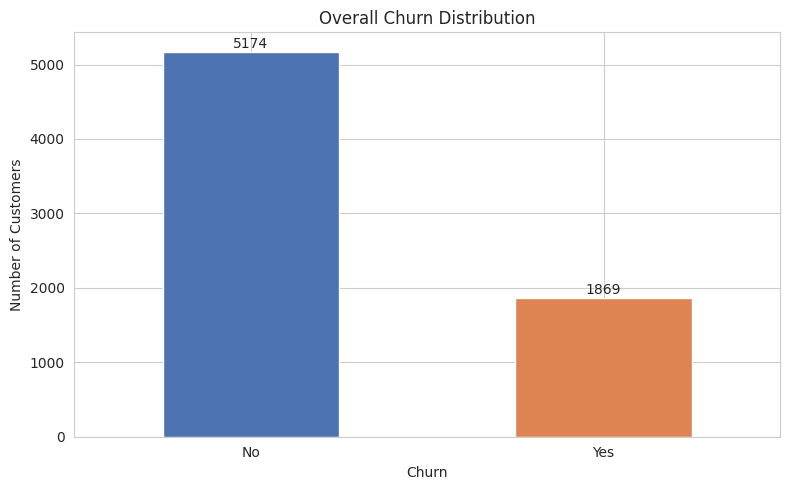

Churn rate: 26.5% of customers churned. This is a moderately imbalanced target.


In [7]:
fig, ax = plt.subplots()
df["Churn"].value_counts().plot(kind="bar", color=["#4C72B0", "#DD8452"], ax=ax)
ax.set_title("Overall Churn Distribution")
ax.set_xlabel("Churn")
ax.set_ylabel("Number of Customers")
for i, v in enumerate(df["Churn"].value_counts()):
    ax.text(i, v + 50, str(v), ha="center")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("churn_overall.png", dpi=100)
plt.show()
print(f"Churn rate: {churn_rate['Yes']:.1f}% of customers churned. This is a moderately imbalanced target.")


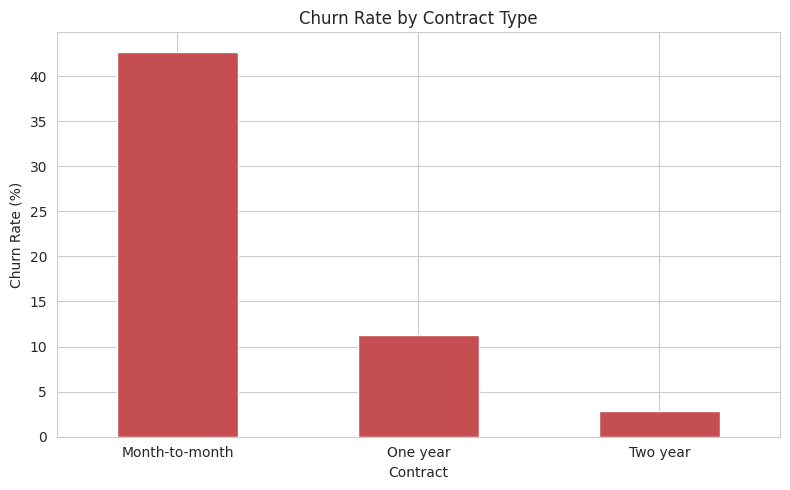

In [8]:
fig, ax = plt.subplots(figsize=(8,5))
churn_by_contract = pd.crosstab(df["Contract"], df["Churn"], normalize="index") * 100
churn_by_contract["Yes"].sort_values(ascending=False).plot(kind="bar", color="#C44E52", ax=ax)
ax.set_ylabel("Churn Rate (%)")
ax.set_title("Churn Rate by Contract Type")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("churn_by_contract.png", dpi=100)
plt.show()


**Takeaway:** Month-to-month customers churn at a dramatically higher rate than customers on 1- or 2-year contracts. Contract type is likely to be one of the strongest predictors.

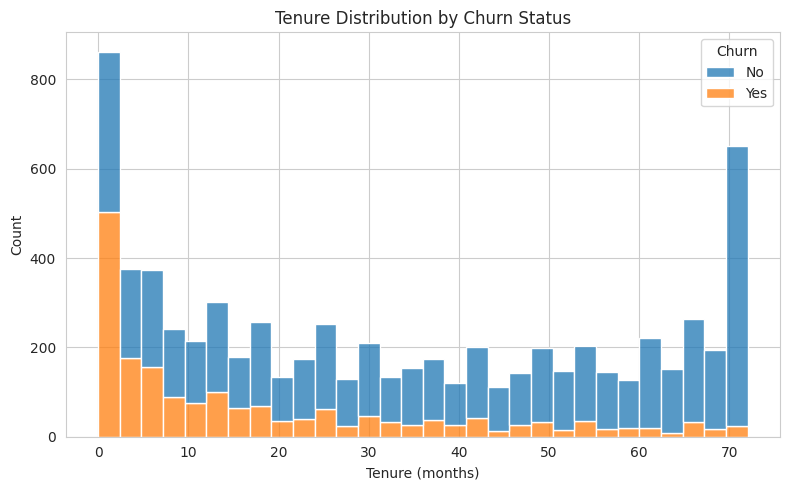

In [9]:
fig, ax = plt.subplots()
sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack", bins=30, ax=ax)
ax.set_title("Tenure Distribution by Churn Status")
ax.set_xlabel("Tenure (months)")
plt.tight_layout()
plt.savefig("churn_by_tenure.png", dpi=100)
plt.show()


**Takeaway:** Churn is heavily concentrated in the first few months of tenure. Customers who make it past ~12-18 months are far less likely to leave — an early-tenure retention window stands out clearly.

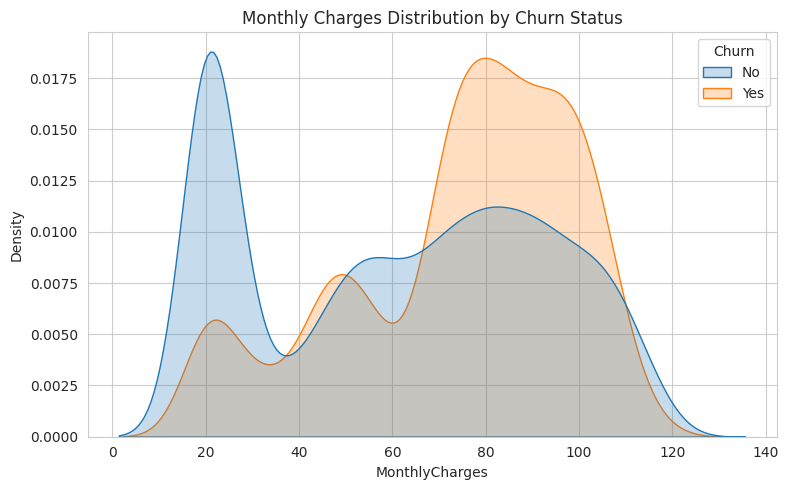

In [10]:
fig, ax = plt.subplots()
sns.kdeplot(data=df, x="MonthlyCharges", hue="Churn", fill=True, common_norm=False, ax=ax)
ax.set_title("Monthly Charges Distribution by Churn Status")
plt.tight_layout()
plt.savefig("churn_by_charges.png", dpi=100)
plt.show()


**Takeaway:** Churned customers skew toward higher monthly charges. Combined with the tenure pattern, this suggests price sensitivity is strongest for customers who haven't yet 'locked in' to the service.

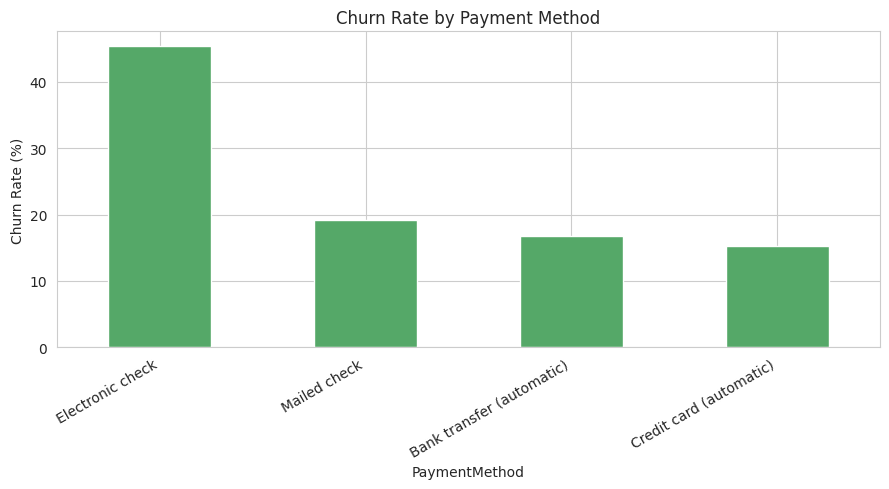

In [11]:
fig, ax = plt.subplots(figsize=(9,5))
churn_by_payment = pd.crosstab(df["PaymentMethod"], df["Churn"], normalize="index") * 100
churn_by_payment["Yes"].sort_values(ascending=False).plot(kind="bar", color="#55A868", ax=ax)
ax.set_ylabel("Churn Rate (%)")
ax.set_title("Churn Rate by Payment Method")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("churn_by_payment.png", dpi=100)
plt.show()


**Takeaway:** Customers paying by electronic check churn at a much higher rate than those on automatic payment methods (bank transfer / credit card). This could reflect less commitment/engagement with the service, or friction in the payment experience.

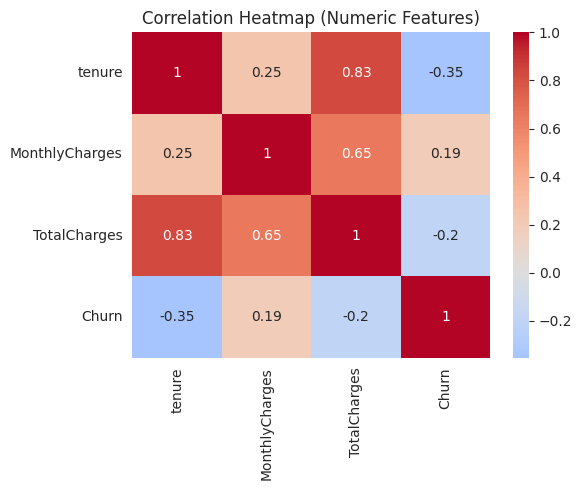

In [12]:
# Correlation heatmap for numeric features (after encoding Churn as 0/1 for reference)
numeric_df = df[["tenure", "MonthlyCharges", "TotalCharges"]].copy()
numeric_df["Churn"] = (df["Churn"] == "Yes").astype(int)

fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation Heatmap (Numeric Features)")
plt.tight_layout()
plt.savefig("correlation_heatmap.png", dpi=100)
plt.show()


**Takeaway:** Tenure is negatively correlated with churn (longer-tenured customers churn less), while monthly charges is positively correlated. TotalCharges is highly correlated with tenure (makes sense — it's roughly tenure × monthly charge), so we should be cautious about multicollinearity if using a linear model.

## 3. Data Preprocessing

Steps:
1. Encode the binary target (`Churn`: Yes/No → 1/0)
2. One-hot encode categorical features
3. Train/test split (stratified, since churn is imbalanced)
4. Scale numeric features (needed for Logistic Regression)


In [13]:
# Encode target
df["Churn"] = (df["Churn"] == "Yes").astype(int)

# Identify categorical columns (excluding target)
cat_cols = df.select_dtypes(include="object").columns.tolist()
print("Categorical columns:", cat_cols)

# One-hot encode
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)
print("Shape after encoding:", df_encoded.shape)


Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Shape after encoding: (7043, 31)


/tmp/ipykernel_567/1896650740.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist()


In [14]:
X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, " Test shape:", X_test.shape)
print("Train churn rate:", y_train.mean().round(3), " Test churn rate:", y_test.mean().round(3))


Train shape: (5634, 30)  Test shape: (1409, 30)
Train churn rate: 0.265  Test churn rate: 0.265


In [15]:
# Scale numeric features (for Logistic Regression). Tree models don't need this,
# but scaling doesn't hurt them, so we keep one consistent feature set for simplicity.
scaler = StandardScaler()
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])


## 4. Modeling

We'll compare three models:
- **Logistic Regression** (interpretable baseline)
- **Random Forest** (non-linear, handles feature interactions)
- **XGBoost** (typically strongest performer for tabular data)

Since churn is imbalanced (~73% / 27%), we use `class_weight="balanced"` (or equivalent) rather than optimizing for raw accuracy, which would be misleading here — a model that always predicts "No churn" would already be ~73% accurate while being useless.

In [16]:
models = {}

# Logistic Regression
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
log_reg.fit(X_train_scaled, y_train)
models["Logistic Regression"] = log_reg

# Random Forest
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1)
rf.fit(X_train_scaled, y_train)
models["Random Forest"] = rf

# XGBoost - use scale_pos_weight to handle imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb = XGBClassifier(
    n_estimators=300, max_depth=4, learning_rate=0.05,
    scale_pos_weight=scale_pos_weight, random_state=42,
    eval_metric="logloss"
)
xgb.fit(X_train_scaled, y_train)
models["XGBoost"] = xgb

print("Models trained:", list(models.keys()))


Models trained: ['Logistic Regression', 'Random Forest', 'XGBoost']


## 5. Model Evaluation

We report Accuracy, Precision, Recall, F1, and ROC-AUC for each model. For a churn use case,
**Recall on the churn class matters most** — missing a customer who's about to churn (false negative)
is usually more costly than flagging a loyal customer for a retention offer (false positive).

In [17]:
results = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    report = classification_report(y_test, y_pred, output_dict=True)
    auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": name,
        "Accuracy": report["accuracy"],
        "Precision (Churn)": report["1"]["precision"],
        "Recall (Churn)": report["1"]["recall"],
        "F1 (Churn)": report["1"]["f1-score"],
        "ROC-AUC": auc
    })

results_df = pd.DataFrame(results).round(3)
results_df


,Model,Accuracy,Precision (Churn),Recall (Churn),F1 (Churn),ROC-AUC
0,Logistic Regression,0.738,0.504,0.783,0.614,0.842
1,Random Forest,0.790,0.633,0.497,0.557,0.825
2,XGBoost,0.752,0.521,0.786,0.627,0.839


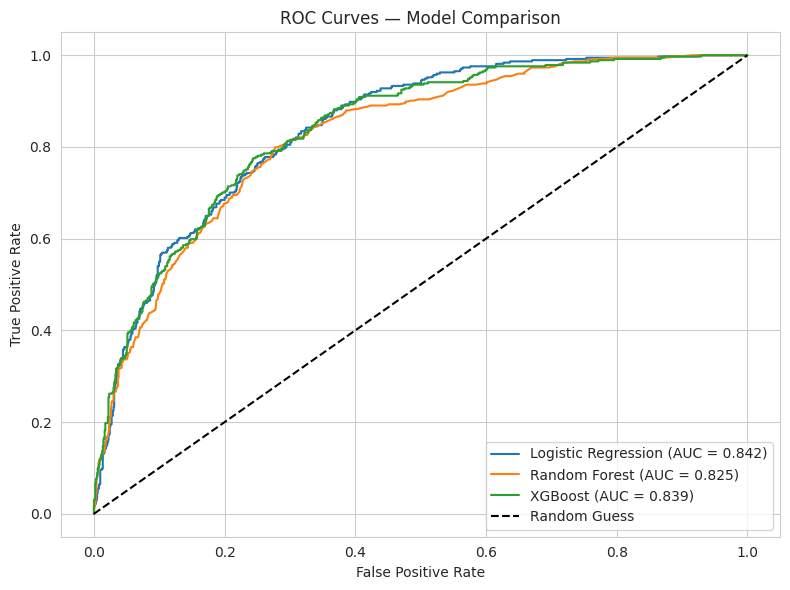

In [18]:
fig, ax = plt.subplots(figsize=(8,6))
for name, model in models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

ax.plot([0,1], [0,1], "k--", label="Random Guess")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — Model Comparison")
ax.legend()
plt.tight_layout()
plt.savefig("roc_curves.png", dpi=100)
plt.show()


Best model by ROC-AUC: Logistic Regression


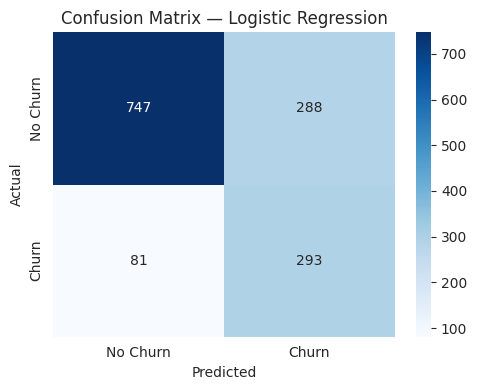

In [19]:
# Confusion matrix for the best model (by ROC-AUC)
best_model_name = results_df.sort_values("ROC-AUC", ascending=False).iloc[0]["Model"]
best_model = models[best_model_name]
print(f"Best model by ROC-AUC: {best_model_name}")

y_pred_best = best_model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_best)

fig, ax = plt.subplots(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"], ax=ax)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=100)
plt.show()


## 6. Feature Importance & Interpretation

We look at what's driving predictions in both the tree-based model (Random Forest / XGBoost feature importance)
and the linear model (Logistic Regression coefficients), since they can offer complementary views.

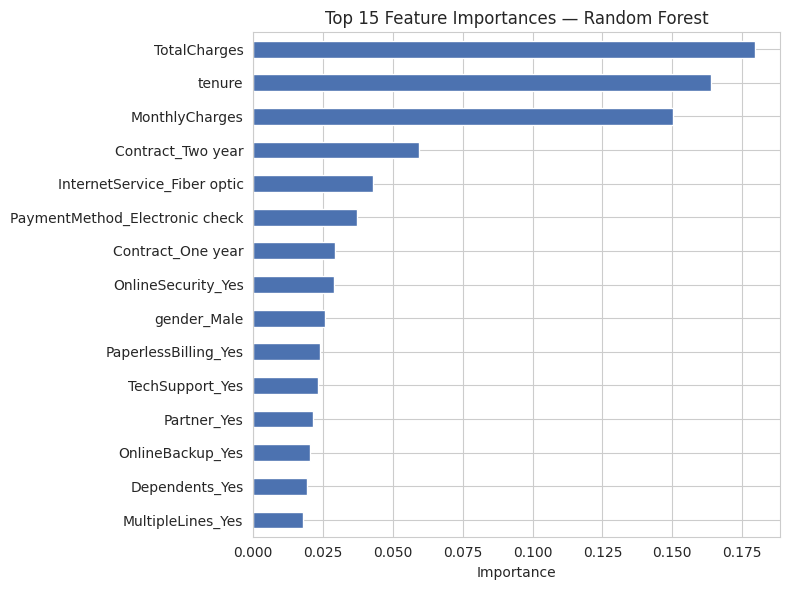

In [20]:
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8,6))
importances.sort_values().plot(kind="barh", ax=ax, color="#4C72B0")
ax.set_title("Top 15 Feature Importances — Random Forest")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=100)
plt.show()


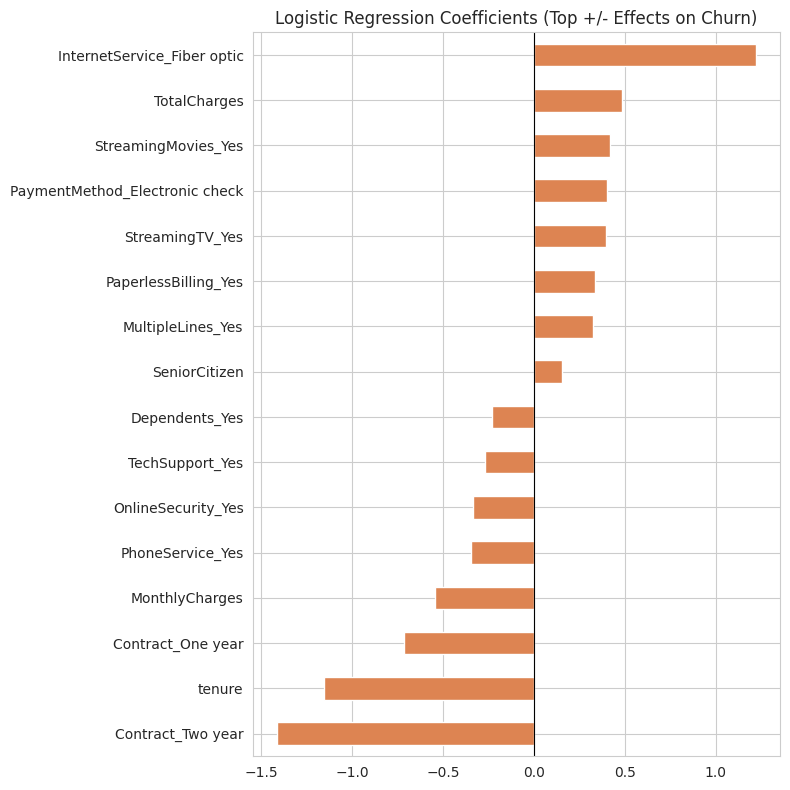

In [21]:
# Logistic regression coefficients (direction of effect)
coefs = pd.Series(log_reg.coef_[0], index=X_train.columns).sort_values()

fig, ax = plt.subplots(figsize=(8,8))
pd.concat([coefs.head(8), coefs.tail(8)]).plot(kind="barh", ax=ax, color="#DD8452")
ax.set_title("Logistic Regression Coefficients (Top +/- Effects on Churn)")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig("logreg_coefficients.png", dpi=100)
plt.show()


**Interpretation:**
- Positive coefficients (right side) increase churn likelihood — e.g., month-to-month contracts, fiber optic internet, electronic check payment.
- Negative coefficients (left side) decrease churn likelihood — e.g., longer tenure, 2-year contracts, having tech support or online security add-ons.
- Both models agree that **contract type and tenure are the dominant drivers**, with monthly charges and specific service add-ons playing a secondary role.


## 7. Business Recommendations

Based on the analysis above, here are concrete, actionable recommendations:

1. **Target the first 12 months.** Churn risk is highest in early tenure. A structured onboarding or early-loyalty program (e.g., a discount or bonus at month 6) could reduce the highest-risk period.

2. **Incentivize longer contracts.** Month-to-month customers churn at far higher rates than those on 1- or 2-year contracts. Offering a modest discount to convert month-to-month customers to annual contracts could meaningfully cut churn.

3. **Investigate the electronic check payment experience.** This group churns disproportionately — this may reflect a segment with generally lower engagement, or friction in the payment method itself worth investigating directly (e.g., through a survey).

4. **Bundle protective services.** Customers without Online Security or Tech Support churn more. Bundling these services (with a mild discount) into base plans could reduce churn while increasing average revenue per customer.

5. **Use the model operationally.** Score all active customers monthly with this model, and route the highest-risk segment (e.g., top 10-15% by predicted churn probability) to a proactive retention team or automated discount offer, rather than treating all customers uniformly.

### Caveats
- This dataset is a single snapshot in time — a production system would need to be retrained on rolling data and monitored for drift.
- The model's precision/recall tradeoff should be tuned based on the actual cost of a false positive (e.g., cost of an unnecessary discount) vs. a false negative (cost of losing a customer), which we did not have here and would come from the business.
